In [4]:
try:
    import random
    import matplotlib.pyplot as plt
    import networkx as nx
    import numpy as np
except Exception as e:
    %pip install matplotlib
    import matplotlib.pyplot as plt
    %pip install networkx
    import networkx as nx

    

In [5]:
ARBOL = [[3, -5, 2], [-5, -7, 4], [-9, 6, -8]]


Valor óptimo obtenido por Alfa-Beta: -5


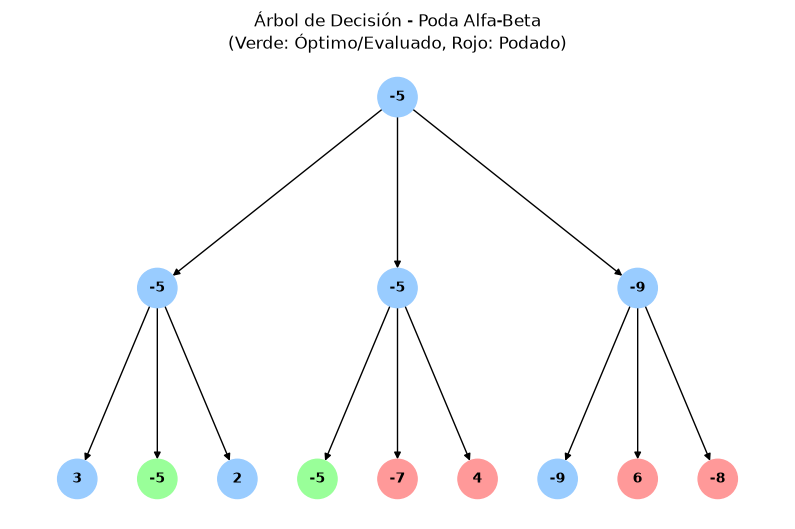

In [6]:
# Celda 3: Algoritmo de Poda Alfa-Beta y Visualización Gráfica


class NodoArbol:

  def __init__(self, valor=None, es_max=True):
    self.valor = valor
    self.hijos = []
    self.es_max = es_max
    self.podado = False
    self.etiqueta = ""


def construir_nodo(estructura, es_max=True):
  """Convierte la lista anidada en una estructura de objetos para un manejo más limpio."""
  nodo = NodoArbol(es_max=es_max)
  if isinstance(estructura, list):
    for sub in estructura:
      nodo.hijos.append(construir_nodo(sub, not es_max))
  else:
    nodo.valor = estructura
  return nodo


def alfa_beta(nodo, profundidad, alfa, beta, es_max):
  """Implementación del algoritmo Alfa-Beta.

  Retorna el valor heurístico y marca los nodos podados.
  """
  if not nodo.hijos:
    return nodo.valor

  if es_max:
    val = -float("inf")
    for hijo in nodo.hijos:
      eval_hijo = alfa_beta(hijo, profundidad + 1, alfa, beta, False)
      val = max(val, eval_hijo)
      alfa = max(alfa, val)
      if beta <= alfa:
        # Marcar nodos restantes de este nivel como podados
        idx = nodo.hijos.index(hijo)
        for h_podado in nodo.hijos[idx + 1:]:
          marcar_como_podados(h_podado)
        break
    nodo.valor = val
    return val
  else:
    val = float("inf")
    for hijo in nodo.hijos:
      eval_hijo = alfa_beta(hijo, profundidad + 1, alfa, beta, True)
      val = min(val, eval_hijo)
      beta = min(beta, val)
      if beta <= alfa:
        idx = nodo.hijos.index(hijo)
        for h_podado in nodo.hijos[idx + 1:]:
          marcar_como_podados(h_podado)
        break
    nodo.valor = val
    return val


def marcar_como_podados(nodo):
  nodo.podado = True
  for h in nodo.hijos:
    marcar_como_podados(h)


# Construcción y ejecución del algoritmo
raiz = construir_nodo(ARBOL, es_max=True)
resultado_optimo = alfa_beta(raiz, 0, -float("inf"), float("inf"), True)
print(f"\nValor óptimo obtenido por Alfa-Beta: {resultado_optimo}")

# Visualización Gráfica usando NetworkX y Matplotlib
def obtener_posiciones(nodo, x=0, y=0, ancho=1.0, pos=None, id_padre=None, contador=None):
  if pos is None:
    pos = {}
    contador = [0]

  nid = contador[0]
  contador[0] += 1
  pos[nid] = (x, y)

  hijos_activos = [h for h in nodo.hijos]
  num_hijos = len(hijos_activos)

  if num_hijos > 0:
    ancho_hijo = ancho / num_hijos
    inicio_x = x - ancho / 2 + ancho_hijo / 2
    for i, hijo in enumerate(hijos_activos):
      hx = inicio_x + i * ancho_hijo
      hy = y - 1
      h_id = obtener_posiciones(
          hijo, hx, hy, ancho_hijo, pos, nid, contador
      )

  return pos


# Graficar el árbol
G = nx.DiGraph()
posiciones = {}
colores_nodos = []
etiquetas_nodos = {}


def poblar_grafo(nodo, G, id_actual=0, contador=None):
  if contador is None:
    contador = [0]

  me_id = contador[0]
  etiquetas_nodos[me_id] = (
      str(nodo.valor) if nodo.valor is not None else ("MAX" if nodo.es_max else "MIN")
  )

  if nodo.podado:
    colores_nodos.append("#ff9999")  # Rojo claro para podados
  elif nodo.valor == resultado_optimo and not nodo.hijos:
    colores_nodos.append("#99ff99")  # Verde para camino óptimo en hojas
  else:
    colores_nodos.append("#99ccff")  # Azul claro estándar

  for hijo in nodo.hijos:
    contador[0] += 1
    h_id = contador[0]
    G.add_edge(me_id, h_id)
    poblar_grafo(hijo, G, h_id, contador)


poblar_grafo(raiz, G)
pos = obtener_posiciones(raiz, x=0, y=0, ancho=4.0)

plt.figure(figsize=(10, 6))
plt.title(
    "Árbol de Decisión - Poda Alfa-Beta\n(Verde: Óptimo/Evaluado, Rojo: Podado)",
    fontsize=12,
)
nx.draw(
    G,
    pos,
    labels=etiquetas_nodos,
    node_color=colores_nodos,
    node_size=800,
    font_size=10,
    font_weight="bold",
    arrows=True,
)
plt.axis("off")
plt.show()